# LAB | sklearn Model Training + Evaluation

**Titanic Data Analysis and JSON Export**

Delivered by Carolina Uchoa - 03rd November, 2026

## Scenario:
You're working as a machine learning intern at consulting company. Your team is developing predictive models to help with early disease detection. In Part 1, you'll work with a guided exercise using the breast cancer dataset to learn the fundamentals of machine learning with sklearn. In Part 2, you'll apply these skills independently to predict customer churn for a telecommunications company.

## Part 1 - Guided:  Breast Cancer Prediction
You'll work through a complete machine learning workflow step-by-step with detailed code and explanations. We'll use the breast cancer dataset to predict whether a tumor is malignant (cancerous) or benign (non-cancerous).

## Part 2 (Unguided): 

You'll apply what you learned to predict customer churn for a telecommunications company. You'll receive the dataset and a list of steps to follow, but you'll write the code yourself.

## What you'll build:
-A KNN classifier for breast cancer prediction
-A customer churn prediction model
-Understanding of the complete ML workflow: load → explore → split → train → evaluate

# Part 1: Guided Exercise - Breast Cancer Prediction

In [44]:
##Description: Predict whether a breast tumor is malignant or benign using KN

#Step 1: Setting Up and Loading Data

import numpy as np #numerical computing library
import pandas as pd #data manipulation and analysis library
import matplotlib.pyplot as plt #data visualization library 
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, classification_report
 
# Load the breast cancer dataset
print("Loading breast cancer dataset...")
cancer_data = load_breast_cancer()
 
# The dataset is a Bunch object with 'data', 'target', 'feature_names', etc.
print(f"\nDataset type: {type(cancer_data)}")
print(f"Number of samples: {len(cancer_data.data)}")
print(f"Number of features: {len(cancer_data.feature_names)}")
print(f"Target classes: {cancer_data.target_names}")
 
# Convert to DataFrame for easier manipulation
df = pd.DataFrame(cancer_data.data, columns=cancer_data.feature_names)
df['target'] = cancer_data.target
 
print("\nFirst few rows:")
print(df.head())
 
print("\nDataset info:")
print(df.info())
 
print("\nTarget distribution:")
print(df['target'].value_counts())
print(f"Malignant (0): {(df['target'] == 0).sum()}")
print(f"Benign (1): {(df['target'] == 1).sum()}")


Loading breast cancer dataset...

Dataset type: <class 'sklearn.utils._bunch.Bunch'>
Number of samples: 569
Number of features: 30
Target classes: ['malignant' 'benign']

First few rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520


BASIC STATISTICS
       mean radius  mean texture  mean perimeter    mean area  \
count   569.000000    569.000000      569.000000   569.000000   
mean     14.127292     19.289649       91.969033   654.889104   
std       3.524049      4.301036       24.298981   351.914129   
min       6.981000      9.710000       43.790000   143.500000   
25%      11.700000     16.170000       75.170000   420.300000   
50%      13.370000     18.840000       86.240000   551.100000   
75%      15.780000     21.800000      104.100000   782.700000   
max      28.110000     39.280000      188.500000  2501.000000   

       mean smoothness  mean compactness  mean concavity  mean concave points  \
count       569.000000        569.000000      569.000000           569.000000   
mean          0.096360          0.104341        0.088799             0.048919   
std           0.014064          0.052813        0.079720             0.038803   
min           0.052630          0.019380        0.000000             0.0

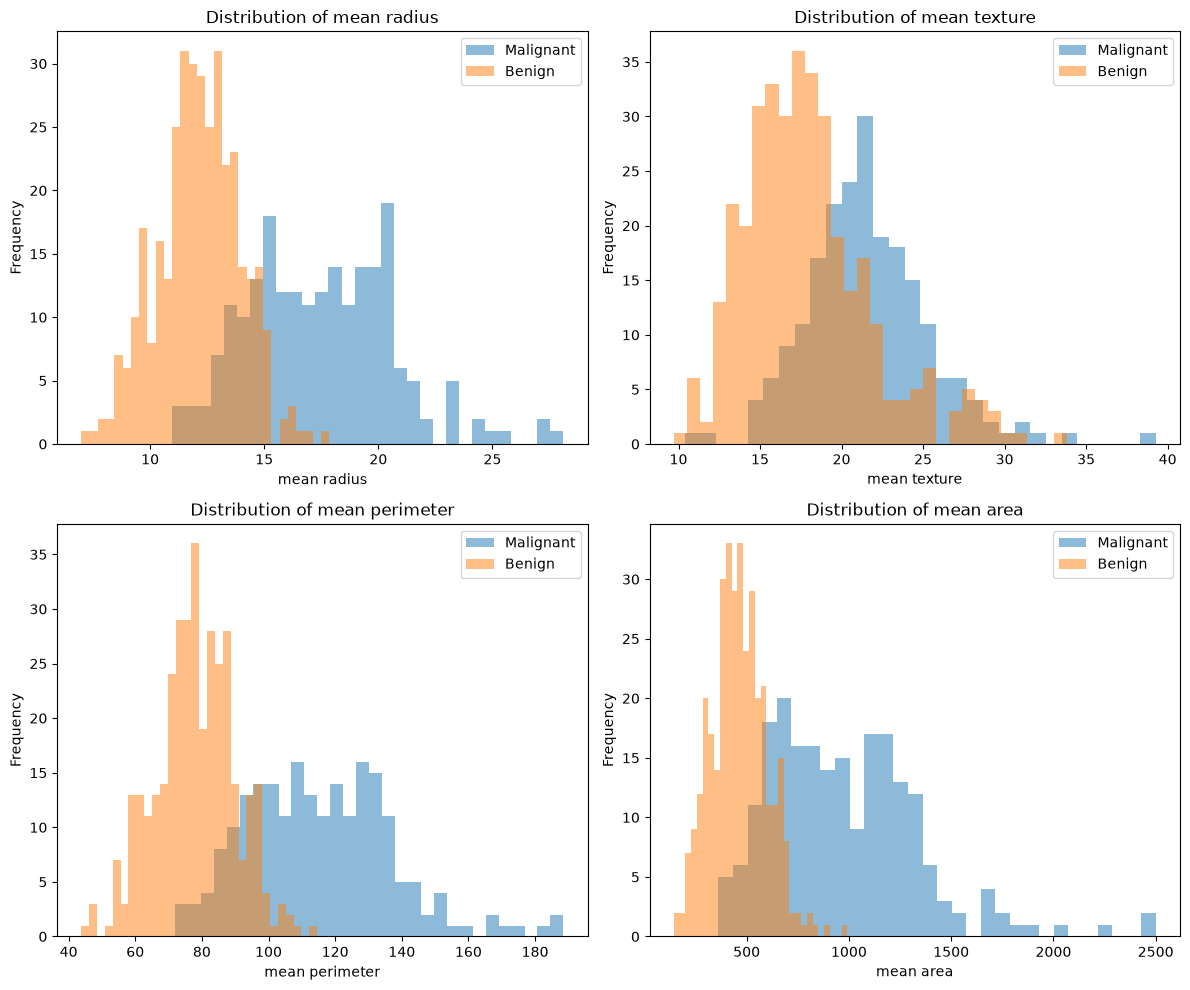

In [45]:
#Step 2: Data Exploration

# Basic statistics
print("\n" + "="*50)
print("BASIC STATISTICS")
print("="*50)
print(df.describe())
 
# Check for missing values
print("\n" + "="*50)
print("MISSING VALUES")
print("="*50)
missing = df.isnull().sum()
if missing.sum() == 0:
    print("✓ No missing values found!")
else:
    print(missing[missing > 0])
 
# Visualize feature distributions (select a few key features)
print("\n" + "="*50)
print("FEATURE DISTRIBUTIONS")
print("="*50)
 
# Select a few representative features to visualize
key_features = ['mean radius', 'mean texture', 'mean perimeter', 'mean area']
 
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()
 
for idx, feature in enumerate(key_features):
    axes[idx].hist(df[df['target'] == 0][feature], alpha=0.5, label='Malignant', bins=30)
    axes[idx].hist(df[df['target'] == 1][feature], alpha=0.5, label='Benign', bins=30)
    axes[idx].set_xlabel(feature)
    axes[idx].set_ylabel('Frequency')
    axes[idx].set_title(f'Distribution of {feature}')
    axes[idx].legend()
 
plt.tight_layout()
plt.savefig('feature_distributions.png', dpi=150, bbox_inches='tight')
print("Saved visualization to 'feature_distributions.png'")
plt.show()

In [46]:
#Step 3: Splitting the Data

# Separate features and target
X = df.drop('target', axis=1)  # All columns except 'target'
y = df['target']  # Target column
 
print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")
 
# Split into training and testing sets
# random_state ensures reproducibility
# stratify=y ensures both sets have similar class distribution
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)
 
print("\n" + "="*50)
print("DATA SPLIT")
print("="*50)
print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size: {X_test.shape[0]} samples")
print(f"Training features: {X_train.shape[1]}")
print(f"Test features: {X_test.shape[1]}")
 
# Verify class distribution in both sets
print("\nTraining set target distribution:")
print(y_train.value_counts())
print(f"  Benign (0): {(y_train == 0).sum()} ({(y_train == 0).mean()*100:.1f}%)")
print(f"  Malignant (1): {(y_train == 1).sum()} ({(y_train == 1).mean()*100:.1f}%)")
 
print("\nTest set target distribution:")
print(y_test.value_counts())
print(f"  Malignant (0): {(y_test == 0).sum()} ({(y_test == 0).mean()*100:.1f}%)")
print(f"  Benign (1): {(y_test == 1).sum()} ({(y_test == 1).mean()*100:.1f}%)")


Features shape: (569, 30)
Target shape: (569,)

DATA SPLIT
Training set size: 455 samples
Test set size: 114 samples
Training features: 30
Test features: 30

Training set target distribution:
target
1    285
0    170
Name: count, dtype: int64
  Benign (0): 170 (37.4%)
  Malignant (1): 285 (62.6%)

Test set target distribution:
target
1    72
0    42
Name: count, dtype: int64
  Malignant (0): 42 (36.8%)
  Benign (1): 72 (63.2%)


In [47]:
#Step 4: Training the KNN Model
# Create KNN classifier
# n_neighbors=5 means the model will look at the 5 nearest neighbors to make a prediction
 
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
 
print("KNN classifier trained successfully!")
print(f"Number of neighbors (k): {knn.n_neighbors}")
 
# Make predictions
y_train_pred = knn.predict(X_train)
y_test_pred = knn.predict(X_test)
 
print(f"\nTraining predictions: {len(y_train_pred)}")
print(f"Test predictions: {len(y_test_pred)}")

KNN classifier trained successfully!
Number of neighbors (k): 5

Training predictions: 455
Test predictions: 114


In [48]:
#Step 5: Making Predictions
# Predictions were created in Step 4:
# y_test_pred = knn.predict(X_test)

# Compare a few predicted values with the actual values
comparison = pd.DataFrame({
    "Actual": y_test.iloc[:10].values,
    "Predicted": y_test_pred[:10]
})

print(comparison)

# Count how many predictions match
# Hint: compare the two columns and use .sum()
correct = (comparison["Actual"] == comparison["Predicted"]).sum()

# Display all predictions if useful
print("All test predictions:")
print(y_test_pred)

   Actual  Predicted
0       0          0
1       1          1
2       0          0
3       1          0
4       0          0
5       1          1
6       1          1
7       0          0
8       0          0
9       0          0
All test predictions:
[0 1 0 0 0 1 1 0 0 0 1 0 1 0 0 1 0 1 1 1 0 0 1 1 1 0 0 1 1 1 1 1 1 1 0 1 1
 1 1 0 1 1 1 0 0 1 1 1 0 0 1 1 1 0 1 1 1 0 0 1 1 1 1 1 0 1 1 1 1 1 1 1 1 0
 0 0 1 1 1 1 0 1 0 1 0 1 1 1 1 1 1 1 0 0 0 1 0 1 0 0 0 0 1 1 0 0 1 0 1 0 1
 0 1 1]


In [49]:
#Step 6: Evaluating Model Performance
# Calculate metrics
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred, pos_label=0)
test_recall = recall_score(y_test, y_test_pred, pos_label=0)
test_confusion = confusion_matrix(y_test, y_test_pred)
 
print("=== Model Performance ===")
print(f"\nTraining Accuracy: {train_accuracy:.4f} ({train_accuracy*100:.2f}%)")
print(f"Test Accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"\nTest Precision: {test_precision:.4f}")
print(f"Test Recall: {test_recall:.4f}")
 
print("\n=== Confusion Matrix ===")
print("                Predicted")
print("              Benign  Malignant")
print(f"Actual Benign    {test_confusion[0,0]:4d}      {test_confusion[0,1]:4d}")
print(f"      Malignant  {test_confusion[1,0]:4d}      {test_confusion[1,1]:4d}")
 
print("\n=== Classification Report ===")
print(classification_report(y_test, y_test_pred, target_names=cancer_data.target_names))

print("              Malignant  Benign")
print(f"Actual Malignant {test_confusion[0,0]:4d}      {test_confusion[0,1]:4d}")
print(f"       Benign    {test_confusion[1,0]:4d}      {test_confusion[1,1]:4d}")

=== Model Performance ===

Training Accuracy: 0.9473 (94.73%)
Test Accuracy: 0.9123 (91.23%)

Test Precision: 0.8636
Test Recall: 0.9048

=== Confusion Matrix ===
                Predicted
              Benign  Malignant
Actual Benign      38         4
      Malignant     6        66

=== Classification Report ===
              precision    recall  f1-score   support

   malignant       0.86      0.90      0.88        42
      benign       0.94      0.92      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.91      0.91       114
weighted avg       0.91      0.91      0.91       114

              Malignant  Benign
Actual Malignant   38         4
       Benign       6        66



EXPERIMENTING WITH DIFFERENT K VALUES
K= 1: Accuracy=0.9211, Precision=0.8667, Recall=0.9286
K= 3: Accuracy=0.9298, Precision=0.9048, Recall=0.9048
K= 5: Accuracy=0.9123, Precision=0.8636, Recall=0.9048
K= 7: Accuracy=0.9298, Precision=0.9048, Recall=0.9048
K= 9: Accuracy=0.9386, Precision=0.9268, Recall=0.9048
K=11: Accuracy=0.9386, Precision=0.9268, Recall=0.9048

Best K value: 9 (Accuracy: 0.9386)

Saved visualization to 'knn_k_comparison.png'


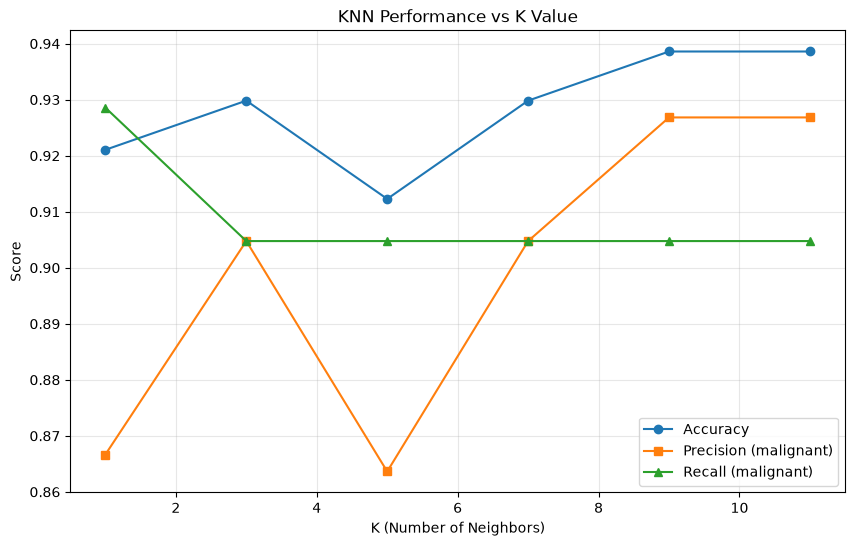

In [50]:
#Step 7: Experimenting with Different K Values

print("\n" + "="*50)
print("EXPERIMENTING WITH DIFFERENT K VALUES")
print("="*50)

k_values = [1, 3, 5, 7, 9, 11]
results = []

for k in k_values:
    # Create and train model
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    knn_temp.fit(X_train, y_train)

    # Make predictions
    y_pred_temp = knn_temp.predict(X_test)

    # Calculate metrics
    # pos_label=0 -> precision and recall measure MALIGNANT tumours (label 0)
    acc = accuracy_score(y_test, y_pred_temp)
    prec = precision_score(y_test, y_pred_temp, pos_label=0)
    rec = recall_score(y_test, y_pred_temp, pos_label=0)

    results.append({
        'K': k,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec
    })

    print(f"K={k:2d}: Accuracy={acc:.4f}, Precision={prec:.4f}, Recall={rec:.4f}")

# Find best K
results_df = pd.DataFrame(results)
best_k = results_df.loc[results_df['Accuracy'].idxmax(), 'K']
print(f"\nBest K value: {best_k} (Accuracy: {results_df['Accuracy'].max():.4f})")

# Visualize results
plt.figure(figsize=(10, 6))
plt.plot(results_df['K'], results_df['Accuracy'], marker='o', label='Accuracy')
plt.plot(results_df['K'], results_df['Precision'], marker='s', label='Precision (malignant)')
plt.plot(results_df['K'], results_df['Recall'], marker='^', label='Recall (malignant)')
plt.xlabel('K (Number of Neighbors)')
plt.ylabel('Score')
plt.title('KNN Performance vs K Value')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('knn_k_comparison.png', dpi=150, bbox_inches='tight')
print("\nSaved visualization to 'knn_k_comparison.png'")
plt.show()

# Part 2: Unguided Exercise - Customer Churn Prediction

# Dataset: 
Telco Customer Churn (Kaggle)

# Data Description:
Contains information about 7,043 customers
Features include: customer demographics, services subscribed, account information
Target: Whether the customer churned (Yes/No)

(7043, 21)
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45    

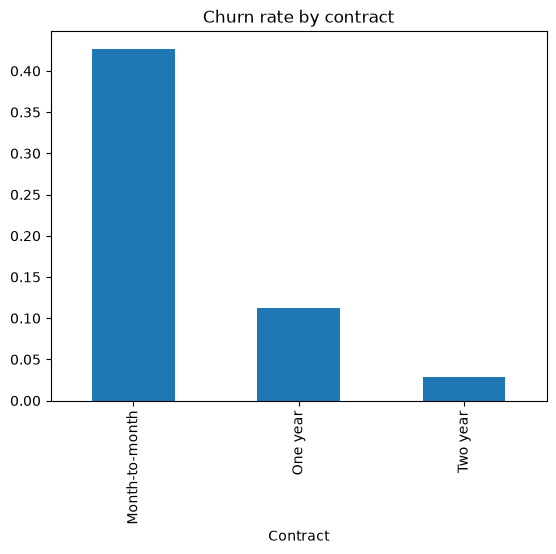

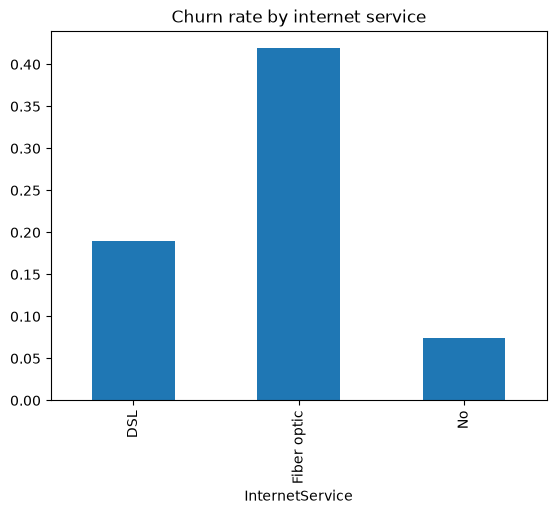

In [51]:
# STEP 1: Load and Explore the Data
##download the churn dataset
##load it into a pandas dataframe
##explore the dataset to understand its structure, features, and target variable
##check the target variable distribution and any missing values


import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             confusion_matrix, classification_report)

DATA_FILE = Path('WA_Fn-UseC_-Telco-Customer-Churn.csv')

# Use the local file if it exists; otherwise download it from Kaggle
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

print(df.shape)       # (7043, 21): 7,043 customers, 21 columns
print(df.dtypes)      # TotalCharges shows as text: it hides blank values
print(df.head())

# Blank TotalCharges values become NaN, so we can count them as missing
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print(df.isnull().sum().sum(), "missing values")   # 11, all in TotalCharges

# Target distribution: counts and percentages
print(df['Churn'].value_counts())
print(df['Churn'].value_counts(normalize=True).round(3) * 100)  # ~26.5% churn

print(df.describe())

#Visualize key features
churn_flag = (df['Churn'] == 'Yes').astype(int)
churn_flag.groupby(df['Contract']).mean().plot(kind='bar', title='Churn rate by contract')
plt.show()
churn_flag.groupby(df['InternetService']).mean().plot(kind='bar', title='Churn rate by internet service')
plt.show()

In [52]:
# STEP 2: Data Preprocessing
#Handle missing values (if any)
#Convert categorical variables to numeric (use encoding techniques)
#Select relevant features for modeling
#Separate features (X) from target (y)
#Convert target to binary (0/1) if needed

df = df.dropna()
df = df.drop(columns=['customerID'])
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})
 
# Turn all text columns into numbers (one-hot encoding)
df = pd.get_dummies(df, drop_first=True, dtype=int)
 
X = df.drop(columns='Churn')
y = df['Churn']

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")

Features shape: (7032, 30)
Target shape: (7032,)


In [53]:
# STEP 3: Split the Data
#Split into training (80%) and testing (20%) sets
#Use stratify to maintain class distribution
#Set random_state=42 for reproducibility

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\n" + "=" * 50)
print("DATA SPLIT")
print("=" * 50)
print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size: {X_test.shape[0]} samples")
print(f"Training features: {X_train.shape[1]}")
print(f"Test features: {X_test.shape[1]}")

# Verify churn distribution
print("\nTraining set churn distribution:")
print(y_train.value_counts())
print(f"  No churn (0): {(y_train == 0).sum()} "
      f"({(y_train == 0).mean() * 100:.1f}%)")
print(f"  Churn (1): {(y_train == 1).sum()} "
      f"({(y_train == 1).mean() * 100:.1f}%)")

print("\nTest set churn distribution:")
print(y_test.value_counts())
print(f"  No churn (0): {(y_test == 0).sum()} "
      f"({(y_test == 0).mean() * 100:.1f}%)")
print(f"  Churn (1): {(y_test == 1).sum()} "
      f"({(y_test == 1).mean() * 100:.1f}%)")


DATA SPLIT
Training set size: 5625 samples
Test set size: 1407 samples
Training features: 30
Test features: 30

Training set churn distribution:
Churn
0    4130
1    1495
Name: count, dtype: int64
  No churn (0): 4130 (73.4%)
  Churn (1): 1495 (26.6%)

Test set churn distribution:
Churn
0    1033
1     374
Name: count, dtype: int64
  No churn (0): 1033 (73.4%)
  Churn (1): 374 (26.6%)


In [54]:
# STEP 4: Train the KNN Model
#Create KNN classifier with k=5
#Fit the model on the training data

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_train_pred = knn.predict(X_train)
y_test_pred = knn.predict(X_test)
 
print("KNN classifier trained successfully!")
print(f"Number of neighbors (k): {knn.n_neighbors}")
 
# Make predictions
y_train_pred = knn.predict(X_train)
y_test_pred = knn.predict(X_test)
 
print(f"\nTraining predictions: {len(y_train_pred)}")
print(f"Test predictions: {len(y_test_pred)}")

KNN classifier trained successfully!
Number of neighbors (k): 5

Training predictions: 5625
Test predictions: 1407


In [55]:
#STEP 5: Make Predictions and Evaluate
#Create predictions on the test set
#Calculate accuracy, precision, recall, and confusion matrix
#Generate a classification report for detailed metrics
#Interpret the results

# Make predictions
y_train_pred = knn.predict(X_train)
y_test_pred = knn.predict(X_test)
 
print(f"\nTraining predictions: {len(y_train_pred)}")
print(f"Test predictions: {len(y_test_pred)}")
 
# Evaluate the model
accuracy = accuracy_score(y_test, y_test_pred)
precision = precision_score(y_test, y_test_pred, zero_division=0)
recall = recall_score(y_test, y_test_pred, zero_division=0)
cm = confusion_matrix(y_test, y_test_pred)

print("\n" + "=" * 50)
print("MODEL EVALUATION")
print("=" * 50)
print(f"Accuracy:  {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["No Churn", "Churn"],
    zero_division=0
))



Training predictions: 5625
Test predictions: 1407

MODEL EVALUATION
Accuracy:  0.746
Precision: 0.528
Recall:    0.428

Confusion Matrix:
[[890 143]
 [214 160]]

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.81      0.86      0.83      1033
       Churn       0.53      0.43      0.47       374

    accuracy                           0.75      1407
   macro avg       0.67      0.64      0.65      1407
weighted avg       0.73      0.75      0.74      1407



In [56]:
# STEP 6: Experiment and Improve
#Try different values of k (e.g., 3, 5, 7, 9) and observe how the performance metrics change
#Compare their performances
#Chose the best k based on accuracy, precision, and recall
#Document your findings and any insights gained from the experiments

# Churn = 1 is the positive class, so these metrics measure churn detection
k_values = [1, 3, 5, 7, 9, 11, 15]
experiment_results = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    experiment_results.append({
        'k': k,
        'accuracy': accuracy_score(y_test, predictions),
        'precision': precision_score(y_test, predictions, zero_division=0),
        'recall': recall_score(y_test, predictions, zero_division=0)
    })

results_df = pd.DataFrame(experiment_results)
print("=== KNN Experiment Results ===")
print(results_df.round(3).to_string(index=False))

best_accuracy_k = int(results_df.loc[results_df['accuracy'].idxmax(), 'k'])
best_precision_k = int(results_df.loc[results_df['precision'].idxmax(), 'k'])
best_recall_k = int(results_df.loc[results_df['recall'].idxmax(), 'k'])

print("\n=== Findings to Document ===")
print(f"Best k for accuracy: {best_accuracy_k}")
print(f"Best k for precision: {best_precision_k}")
print(f"Best k for recall: {best_recall_k}")
print("Recommendation: prioritize the k with the highest recall when identifying customers at risk of churn.")

# Keep the accuracy-selected model available for the next step
best_k = best_accuracy_k
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train, y_train)
y_test_pred = knn.predict(X_test)
print(f"\nFinal model uses k={best_k}.")

=== KNN Experiment Results ===
 k  accuracy  precision  recall
 1     0.709      0.455   0.468
 3     0.738      0.509   0.441
 5     0.746      0.528   0.428
 7     0.766      0.577   0.452
 9     0.762      0.574   0.404
11     0.770      0.600   0.401
15     0.767      0.599   0.372

=== Findings to Document ===
Best k for accuracy: 11
Best k for precision: 11
Best k for recall: 1
Recommendation: prioritize the k with the highest recall when identifying customers at risk of churn.

Final model uses k=11.


=== 1. Model accuracy ===
Final model (k=7) accuracy: 0.766
Baseline (always 'no churn'): 0.734
Recall (churners caught): 0.452

=== 2. Features most related to churn ===
Linked to MORE churn:
SeniorCitizen                     0.15
PaperlessBilling_Yes              0.19
MonthlyCharges                    0.19
PaymentMethod_Electronic check    0.30
InternetService_Fiber optic       0.31
Name: Churn, dtype: float64

Linked to LESS churn:
tenure                                -0.35
Contract_Two year                     -0.30
OnlineBackup_No internet service      -0.23
StreamingMovies_No internet service   -0.23
StreamingTV_No internet service       -0.23
Name: Churn, dtype: float64


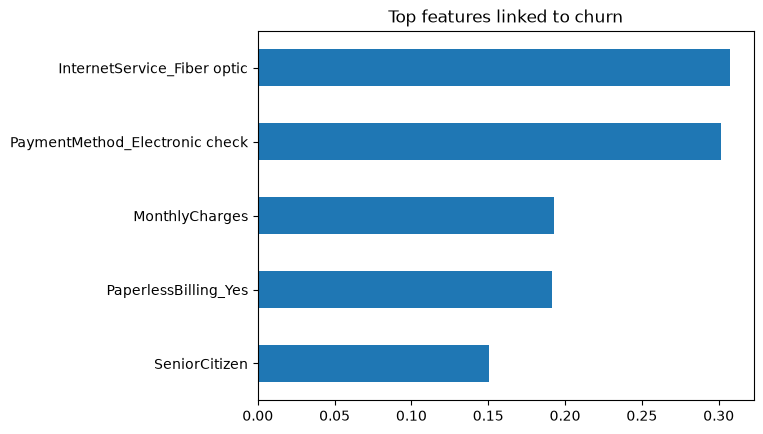


== 3. Recommendations ==
- Target retention at month-to-month, new and fiber optic customers.
- To offer incentives to move customers to 1- or 2-year contracts.
- Review the fiber optic offer (price and service quality).
- Encourage automatic payment methods to facilitate. Electronic-check customers churn more.
- Use the model as an early-warning list: a retention offer costs
  less than losing a customer, so some false alarms are acceptable.

== 4. Limitations ==
- Accuracy is only slightly above the baseline, and the model misses
  more than half of the churners (low recall).
- KNN does not explain WHY a customer churns.
- Results come from a single train/test split.
- Next steps: scale the features, try Logistic Regression or Random
  Forest, and use cross-validation.



In [57]:
# STEP 7: ANALYSIS AND RECOMMENDATIONS
final_knn = KNeighborsClassifier(n_neighbors=7).fit(X_train, y_train)
final_pred = final_knn.predict(X_test)
baseline = 1 - y_test.mean()

# 1. Model accuracy (compared with the baseline)
print("=== 1. Model accuracy ===")
print(f"Final model (k=7) accuracy: {accuracy_score(y_test, final_pred):.3f}")
print(f"Baseline (always 'no churn'): {baseline:.3f}")
print(f"Recall (churners caught): {recall_score(y_test, final_pred):.3f}")

# 2. Most important features: correlation of each feature with Churn
print("\n=== 2. Features most related to churn ===")
corr = df.corr()['Churn'].drop('Churn').sort_values()
print("Linked to MORE churn:")
print(corr.tail(5).round(2))
print("\nLinked to LESS churn:")
print(corr.head(5).round(2))

corr.tail(5).plot(kind='barh', title='Top features linked to churn')
plt.show()

# 3. Recommendations and 4. Limitations
print("""
== 3. Recommendations ==
- Target retention at month-to-month, new and fiber optic customers.
- To offer incentives to move customers to 1- or 2-year contracts.
- Review the fiber optic offer (price and service quality).
- Encourage automatic payment methods to facilitate. Electronic-check customers churn more.
- Use the model as an early-warning list: a retention offer costs
  less than losing a customer, so some false alarms are acceptable.

== 4. Limitations ==
- Accuracy is only slightly above the baseline, and the model misses
  more than half of the churners (low recall).
- KNN does not explain WHY a customer churns.
- Results come from a single train/test split.
- Next steps: scale the features, try Logistic Regression or Random
  Forest, and use cross-validation.
""")